## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Vivian Le

**Date:** 10/21/2026

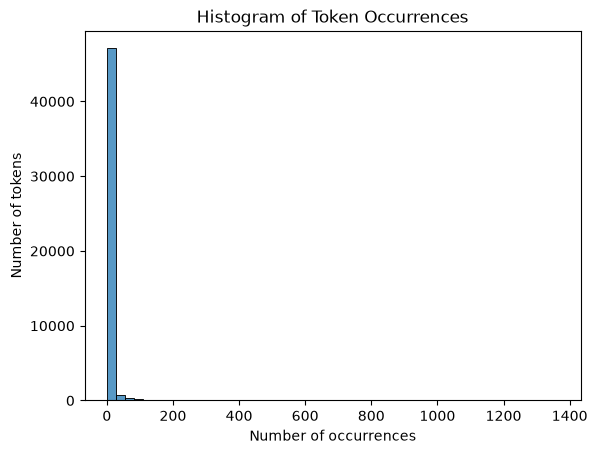

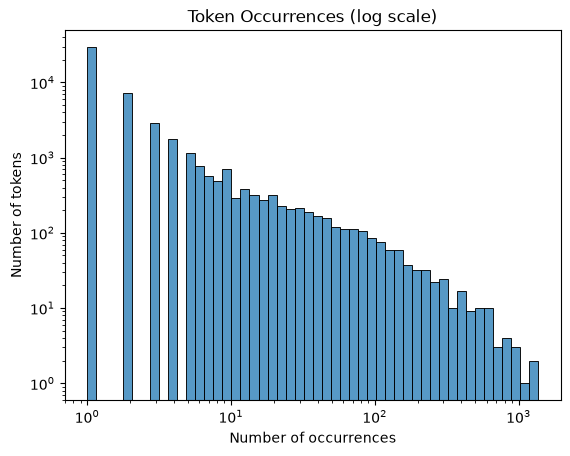

count    48691.000000
mean         5.687889
std         27.717476
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max       1365.000000
Name: count, dtype: float64
Share of tokens appearing once: 60.4%


In [2]:
# Your Phase 1 solution to the problem goes here.

# Q1.

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame(token_freq, columns=['token', 'count'])

sns.histplot(df['count'], bins=50)
plt.title('Histogram of Token Occurrences')
plt.xlabel('Number of occurrences')
plt.ylabel('Number of tokens')
plt.show()

sns.histplot(df['count'], bins=50, log_scale=True)
plt.yscale('log')
plt.title('Token Occurrences (log scale)')
plt.xlabel('Number of occurrences')
plt.ylabel('Number of tokens')
plt.show()

print(df['count'].describe())
print(f"Share of tokens appearing once: {(df['count'] == 1).mean():.1%}")


Q1. The frequency distribution of the tokens is strongly right-skewed. On the regular histogram, almost all tokens fall into the first bar, with a long, flat tail stretching up to around 1,400. Most tokens are rare: the median token appears only once, about 60% of the 48,691 unique tokens appear exactly once, and 75% appear twice or less. A few tokens, such as "new," "date," "get," and "please," appear more than 1,000 times each, which pulls the average up to around 5.7. On a log scale, the histogram looks close to a straight line with a negative slope. This is a power-law pattern, consistent with Zipf's law: a few words are used constantly, while most words are used only once or twice. For machine learning, this means most tokens are too rare to be useful as individual features, and the frequent tokens carry most of the information.

In [3]:
# Q2.

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('data/Phishing_clean.parquet')

y = df['Email Type']
X = df.drop('Email Type', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

reg = LinearRegression().fit(X_train, y_train)

print('Train R^2:', reg.score(X_train, y_train))
print('Test R^2:', reg.score(X_test, y_test))

results = pd.DataFrame({'variable': X.columns, 'coefficient': reg.coef_})
results['abs_coefficient'] = results['coefficient'].abs()
results.sort_values('abs_coefficient', ascending=False).head(15)

Train R^2: 0.7680301260237321
Test R^2: 0.6587519780798341


,variable,coefficient,abs_coefficient
1504,background-image:,-0.891476,0.891476
740,localized,0.815698,0.815698
1406,"helvetica,",0.717349,0.717349
2362,thermal,0.706216,0.706216
906,aging,0.622411,0.622411
2566,transcript,0.578132,0.578132
2559,april's,-0.546313,0.546313
1494,retrieving,-0.527824,0.527824
818,cnet,-0.510492,0.510492
2657,zdnet,-0.503465,0.503465


Q2. After an 80/20 train-test split, the linear regression of Email Type on the 2,711 one-hot-encoded tokens has an R^2 of 0.768 on the training set and 0.659 on the test set. The model explains a fair amount of the variation in whether an email is a scam, but it does noticeably worse on unseen data, which suggests some overfitting from using so many features. The words that have the largest coefficients in terms of absolute values are "background-image:" (-0.89), "localized" (0.82), "helvetica," (0.72), "thermal" (0.71), "aging" (0.62), "transcript" (0.58), "april's" (-0.55), "retrieving" (-0.53), "cnet" (-0.51), "zdnet" (-0.50), and "xanaax" (0.50). Positive coefficients move the prediction toward the category of scam, while negative coefficients move it toward the category of not scam. The majority of these terms do not seem to be obviously associated with scams. Most of them are either HTML/CSS formatting terms ("background-image:", "helvetica,") or infrequent words, which occur in only about 10 to 60 emails. As these terms are infrequent, the model can attribute very large coefficients to them to explain some specific emails, so they have a high impact on predictions but are probably not robust predictors. One exception is the misspelling "xanaax," which is typical for spam.

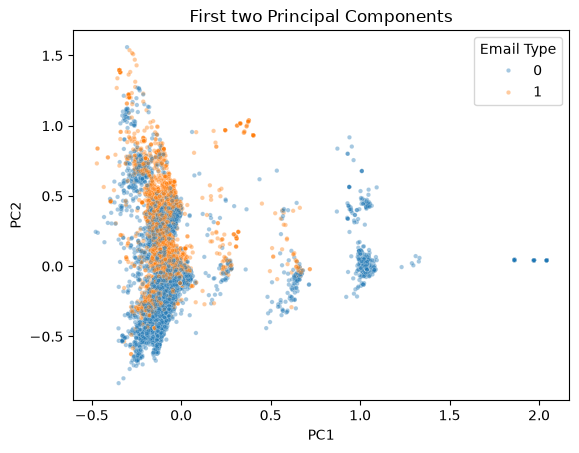

Explained variance ratio: [0.01113087 0.00860781]
date         0.674199
url:         0.367667
start        0.287317
hour         0.260479
hourahead    0.255584
ancillary    0.194638
schedules    0.194281
required     0.063291
Name: PC1, dtype: float64
new         0.449563
like        0.413956
get         0.330182
would       0.319341
hello       0.141321
offer       0.133233
software    0.122784
one         0.113102
Name: PC2, dtype: float64
please     -0.209501
message    -0.152040
call       -0.136394
attached   -0.129356
enron      -0.114477
Name: PC2, dtype: float64


In [4]:
#Q3.

from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
Z = pca.fit_transform(X)

pc = pd.DataFrame(Z, columns = ['PC1', 'PC2'])
pc['Email Type'] = y.values

sns.scatterplot(data=pc, x='PC1', y='PC2', hue='Email Type', alpha=0.4, s=10)
plt.title('First two Principal Components')
plt.show()

print('Explained variance ratio:', pca.explained_variance_ratio_)

loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=['PC1', 'PC2'])
print(loadings['PC1'].sort_values(ascending=False).head(8))
print(loadings['PC2'].sort_values(ascending=False).head(8))
print(loadings['PC2'].sort_values().head(5))

Q3.

The scatter plot shows some separation between phishing and non-phishing emails, but a lot of overlap. Most emails of both types sit in one dense cloud near PC1 ≈ 0. Within that cloud, phishing emails (orange) tend to have higher PC2 values and legitimate emails (blue) tend to have lower PC2 values. Along PC1, the long tail to the right is almost entirely legitimate emails, which form several distinct vertical clusters around PC1 ≈ 0.6, 1.0, and 2.0. Phishing emails almost never have large PC1 values. Looking at the loadings explains this. PC1 is driven mostly by "date," "url:," "start," "hour," "hourahead," "ancillary," and "schedules," which are words from automated Enron energy-scheduling emails, so the clusters on the right are groups of near-identical legitimate business emails. PC2 is positive for "new," "like," "get," "would," "hello," "offer," and "software," which are common in sales or spam emails, and negative for "please," "message," "call," "attached," and "enron," which are common in workplace emails. That is why scams sit higher on PC2. However, these two components account for only about 2% of the total variance in the token data (1.1% and 0.9%), so they capture only a small part of the information in the 2,711 tokens. Principal Component Analysis is an unsupervised approach, so the components do not use the labels and are not chosen to separate scams from legitimate emails; any separation we see is a side effect of differences in word usage.

In [5]:
# Q4.

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

X_train32 = X_train.astype('float32')
X_test32 = X_test.astype('float32')

pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train32)
Z_test = pca.transform(X_test32)

reg_pca = LinearRegression().fit(Z_train, y_train)

print('Train R^2:', reg_pca.score(Z_train, y_train))
print('Test R^2:', reg_pca.score(Z_test, y_test))
print('Variance explained by 2,610 PCs:', pca.explained_variance_ratio_.sum())

Train R^2: 0.767333447933197
Test R^2: 0.659709632396698
Variance explained by 2,610 PCs: 0.99984914


Q4.

Using the first 2610 principal components, the linear regression has an R^2 of 0.767 on the training set and 0.660 on the test set. This is almost identical to the original linear regression on all 2711 tokens (0.768 train, 0.659 test). The 2610 components account for 99.98% of the variance in the token data, so they preserve almost all of the variation in the original of features. The roughly 100 components that were dropped hold only a tiny, almost negligible fraction of the variance. So using PCA here does not improve performance. It only changes the organization of the existing data to create a completely new set of features. It still suffers from overfitting just like before, because the gap between training and test R^2 is the same, at approximately 0.11. PCA would only help if we kept far fewer components, trading a small loss in training fit for a simpler model that might generalize better. A drawback of the PCA version is that the coefficients are on components rather than words, so they are much harder to interpret than the word coefficients in Q2. In addition, the default PCA ran out of memory on my computer, so I converted the data to float32 first, which uses half the memory and gives the same results.

Q5.

The main advantage is that principal components are uncorrelated, while many of the original tokens are strongly correlated (for example, "date," "hour," and "hourahead" often appear together in automated Enron emails). Because the variables are correlated, the regression estimates become unstable, but since the components are orthogonal to each other, this problem disappears. Also, the components are ranked according to the amount of variance explained, so only the most important components can be retained, and the other components can be ignored, since they mainly contain noise contributed by the rare words. This makes the model even more simple and less likely to overfit. In contrast, with the original data, there is no straightforward way of choosing which tokens to remove. In Q4 we kept almost all the components, so results barely changed; the real benefit comes from keeping far fewer.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 7cad216
- **AI tool and model used:** GPT -6 model family

### *Prompts used

1. Review my code and markups for correctedness, but do not rewrite them.

### *AI-proposed changes


Q2 — Linear regression
Status: Good, no major changes needed.
- Your explanation of the training R² (0.768) and test R² (0.659) is correct.
- Your interpretation of positive and negative coefficients makes sense.
- Your discussion of rare words potentially contributing to overfitting is reasonable.
- Minor suggestion: Instead of implying that rare words necessarily cause overfitting, emphasize that they may make the model more sensitive to specific emails.
- Your observation that most of the largest coefficients are not obviously associated with scams is reasonable.
Q3 — PCA visualization
Status: Good, no major changes needed.
- You correctly explain the overlap between phishing and legitimate emails.
- Your interpretation of PC1 and PC2 is supported by the loadings.
- You correctly mention that PCA is unsupervised.
- Minor suggestion: Be cautious about attributing the clusters on PC1 entirely to automated Enron emails. The loadings support this interpretation, but they don't definitively prove it.
- Your statement that the first two components explain approximately 2% of the variance is accurate.
- Your explanation that PCA does not specifically try to separate scams from legitimate emails is correct.
Q4 — PCA regression
Status: Results look correct.
- Your PCA regression has a training R² of 0.7673 and test R² of 0.6597.
- The original regression has a training R² of 0.7680 and test R² of 0.6588.
- The PCA model performs only slightly better on the test set.
- Important suggestion: If your original explanation says PCA preserves almost all the "information," change that to "variation." Your 2,610 components explain 99.9849% of the variance, but that doesn't guarantee they preserve all predictive information.
- Don't claim that PCA significantly improves performance, because the difference is extremely small.
- Your code correctly fits PCA on the training set and transforms the test set, avoiding data leakage.
Q5 — Advantages of PCA
Status: Good overall, but a few technical corrections recommended.
- Your explanation of correlated tokens and multicollinearity is correct.
- Your example involving "date," "hour," and "hourahead" is useful.
- Minor suggestion: The phrase "this problem disappears" is a little too strong. PCA eliminates correlations between the retained components, but it doesn't necessarily solve other regression issues.
- Important suggestion: Instead of saying PCA retains the "most important components," specify that it retains the components explaining the most variance. High variance does not necessarily mean high predictive importance.
- Important suggestion: Remove or qualify the statement that discarded components "mainly contain noise contributed by the rare words." Low-variance components may still contain useful predictive information.
- Minor suggestion: Instead of saying PCA makes the model less likely to overfit, clarify that reducing the number of components can potentially reduce overfitting, but it isn't guaranteed.
- Your final sentence about the benefits of keeping fewer components is reasonable, but clarify that predictive performance should remain similar.
Final verdict
Question	Need to change?
Q2	Optional minor clarification
Q3	Optional minor clarification
Q4	One terminology correction, if applicable
Q5	A few technical wording corrections

I would prioritize Q5, especially the statements about discarded components containing noise and high-variance components being the most important.

Q2 and Q3 are already strong, and Q4's results are consistent with your interpretation.

Your code doesn't need any changes based on the results you've shared. The main improvements are in the written explanations, not the Python implementation.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1. Clarify that rare words may contribute to overfitting (Q2) | Reject | I already addressed this in my original response by explaining that infrequent words can receive large coefficients but may not be robust predictors. Since I already noted this in my original answer, I didn't change it. |
| 2. Interpret PCA clusters more cautiously (Q3) | Reject | My original explanation already acknowledged that phishing and legitimate emails overlap considerably. I decided to keep my interpretation of the clusters based on the PCA loadings, although I recognize that the loadings alone cannot definitively confirm the types of emails in each cluster. |
| 3. Distinguish between variance and predictive information (Q4) | Accept | I changed "information" to "variation" because PCA preserves variance, but does not necessarily preserve all predictive information. I verified that the 2,610 principal components explain approximately 99.98% of the variance, but this does not guarantee that they retain all the information needed to predict scams. |
| 4. Explain how PCA solves the issue of multicollinearity (Q5) | Accept | I changed my answer by replacing the statement that the problem becomes non-existent and how PCA addresses the problem of multicollinearity. Despite the principal components being uncorrelated, PCA is not a panacea for all problems with the regression model. |
| 5. Explain how principal components are selected (Q5) | Accept | I specified that PCA sorts principal components based on the amount of variation they capture. |
| 6. Remove the assumption that discarded components mainly contain noise (Q5) | Accept | I removed this claim because components explaining little variance may still contain useful information for predicting scams. PCA alone cannot determine whether those components are just noise. |
| 7. Clarify that PCA may reduce overfitting (Q5) | Accept | I revised my explanation to clarify that reducing dimensionality can potentially reduce overfitting, but does not guarantee better performance. The nearly identical training and test R^2 values in Q2 and Q4 show that PCA did not meaningfully improve performance in this case. |
| 8. Clarify the benefit of retaining fewer components (Q5) | Accept | I clarified that using fewer components is most beneficial when predictive performance remains similar. In Q4, retaining 2,610 components produced nearly identical R² values to the original regression using 2,711 features, suggesting that greater dimensionality reduction would be needed to see a substantial simplification. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

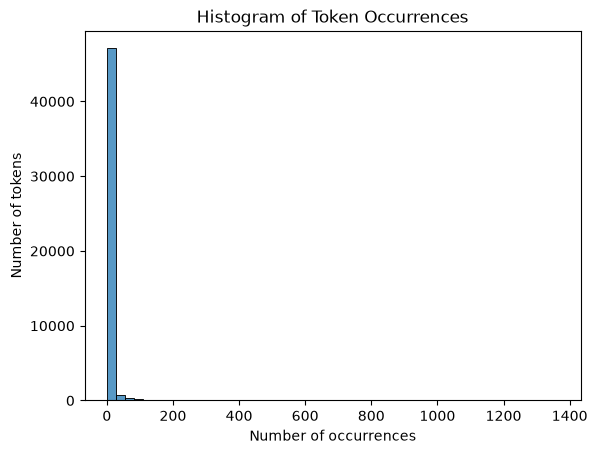

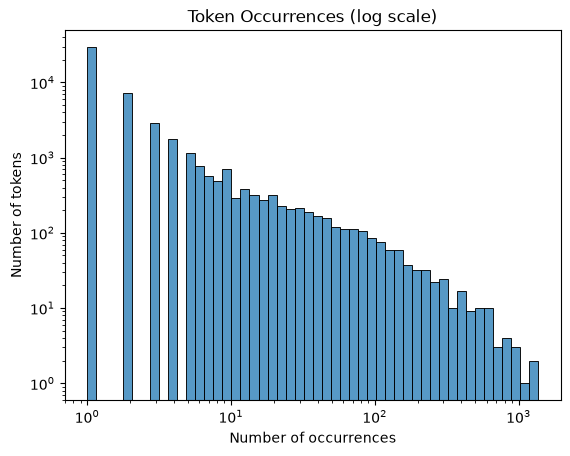

count    48691.000000
mean         5.687889
std         27.717476
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max       1365.000000
Name: count, dtype: float64
Share of tokens appearing once: 60.4%


In [6]:
# Your Phase 2 solution to the problem goes here.

# Q1.

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame(token_freq, columns=['token', 'count'])

sns.histplot(df['count'], bins=50)
plt.title('Histogram of Token Occurrences')
plt.xlabel('Number of occurrences')
plt.ylabel('Number of tokens')
plt.show()

sns.histplot(df['count'], bins=50, log_scale=True)
plt.yscale('log')
plt.title('Token Occurrences (log scale)')
plt.xlabel('Number of occurrences')
plt.ylabel('Number of tokens')
plt.show()

print(df['count'].describe())
print(f"Share of tokens appearing once: {(df['count'] == 1).mean():.1%}")



Q1. The frequency distribution of the tokens is strongly right-skewed. On the regular histogram, almost all tokens fall into the first bar, with a long, flat tail stretching up to around 1,400. Most tokens are rare: the median token appears only once, about 60% of the 48,691 unique tokens appear exactly once, and 75% appear twice or less. A few tokens, such as "new," "date," "get," and "please," appear more than 1,000 times each, which pulls the average up to around 5.7. On a log scale, the histogram looks close to a straight line with a negative slope. This is a power-law pattern, consistent with Zipf's law: a few words are used constantly, while most words are used only once or twice. For machine learning, this means most tokens are too rare to be useful as individual features, and the frequent tokens carry most of the information.

In [7]:
# Q2.

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('data/Phishing_clean.parquet')

y = df['Email Type']
X = df.drop('Email Type', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

reg = LinearRegression().fit(X_train, y_train)

print('Train R^2:', reg.score(X_train, y_train))
print('Test R^2:', reg.score(X_test, y_test))

results = pd.DataFrame({'variable': X.columns, 'coefficient': reg.coef_})
results['abs_coefficient'] = results['coefficient'].abs()
results.sort_values('abs_coefficient', ascending=False).head(15)

Train R^2: 0.7680301260237321
Test R^2: 0.6587519780798341


,variable,coefficient,abs_coefficient
1504,background-image:,-0.891476,0.891476
740,localized,0.815698,0.815698
1406,"helvetica,",0.717349,0.717349
2362,thermal,0.706216,0.706216
906,aging,0.622411,0.622411
2566,transcript,0.578132,0.578132
2559,april's,-0.546313,0.546313
1494,retrieving,-0.527824,0.527824
818,cnet,-0.510492,0.510492
2657,zdnet,-0.503465,0.503465


Q2. After an 80/20 train-test split, the linear regression of Email Type on the 2,711 one-hot-encoded tokens has an R^2 of 0.768 on the training set and 0.659 on the test set. The model explains a fair amount of the variation in whether an email is a scam, but it does noticeably worse on unseen data, which suggests some overfitting from using so many features. The words that have the largest coefficients in terms of absolute values are "background-image:" (-0.89), "localized" (0.82), "helvetica," (0.72), "thermal" (0.71), "aging" (0.62), "transcript" (0.58), "april's" (-0.55), "retrieving" (-0.53), "cnet" (-0.51), "zdnet" (-0.50), and "xanaax" (0.50). Positive coefficients move the prediction toward the category of scam, while negative coefficients move it toward the category of not scam. The majority of these terms do not seem to be obviously associated with scams. Most of them are either HTML/CSS formatting terms ("background-image:", "helvetica,") or infrequent words, which occur in only about 10 to 60 emails. As these terms are infrequent, the model can attribute very large coefficients to them to explain some specific emails, so they have a high impact on predictions but are probably not robust predictors. One exception is the misspelling "xanaax," which is typical for spam.

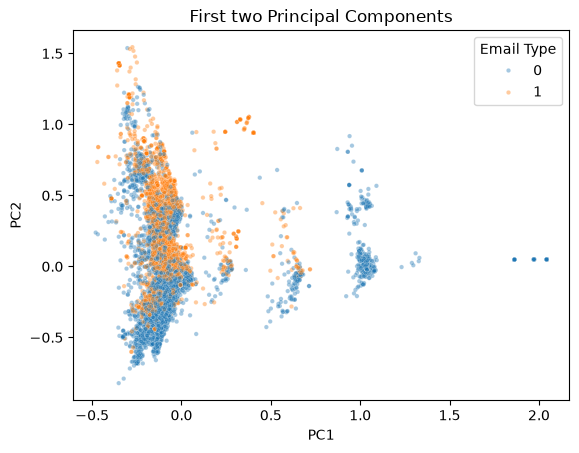

Explained variance ratio: [0.01113091 0.00861143]
date         0.674049
url:         0.367442
start        0.287394
hour         0.260572
hourahead    0.255673
ancillary    0.194712
schedules    0.194351
required     0.063307
Name: PC1, dtype: float64
new         0.447311
like        0.415247
get         0.321416
would       0.319148
hello       0.144472
offer       0.137594
software    0.128802
one         0.113357
Name: PC2, dtype: float64
please     -0.204451
message    -0.146825
attached   -0.132792
call       -0.132482
enron      -0.113193
Name: PC2, dtype: float64


In [8]:
#Q3.

from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
Z = pca.fit_transform(X)

pc = pd.DataFrame(Z, columns = ['PC1', 'PC2'])
pc['Email Type'] = y.values

sns.scatterplot(data=pc, x='PC1', y='PC2', hue='Email Type', alpha=0.4, s=10)
plt.title('First two Principal Components')
plt.show()

print('Explained variance ratio:', pca.explained_variance_ratio_)

loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=['PC1', 'PC2'])
print(loadings['PC1'].sort_values(ascending=False).head(8))
print(loadings['PC2'].sort_values(ascending=False).head(8))
print(loadings['PC2'].sort_values().head(5))

Q3.

The scatter plot shows some separation between phishing and non-phishing emails, but a lot of overlap. Most emails of both types sit in one dense cloud near PC1 ≈ 0. Within that cloud, phishing emails (orange) tend to have higher PC2 values and legitimate emails (blue) tend to have lower PC2 values. Along PC1, the long tail to the right is mostly legitimate emails, which form distinct vertical clusters around PC1 ≈ 0.6 and 1.0, plus a few isolated points near 2.0. Phishing emails rarely appear beyond PC1 ≈ 0.7. Looking at the loadings explains this. PC1 is driven mostly by "date," "url:," "start," "hour," "hourahead," "ancillary," and "schedules," which are words from automated Enron energy-scheduling emails, so the clusters on the right are groups of near-identical legitimate business emails. PC2 is positive for "new," "like," "get," "would," "hello," "offer," and "software," which are common in sales or spam emails, and negative for "please," "message," "call," "attached," and "enron," which are common in workplace emails. That is why scams sit higher on PC2. However, these two components account for only about 2% of the total variance in the token data (1.1% and 0.9%), so they capture only a small part of the information in the 2,711 tokens. Principal Component Analysis is an unsupervised approach, so the components do not use

In [9]:
# Q4.

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

X_train32 = X_train.astype('float32')
X_test32 = X_test.astype('float32')

pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train32)
Z_test = pca.transform(X_test32)

reg_pca = LinearRegression().fit(Z_train, y_train)

print('Train R^2:', reg_pca.score(Z_train, y_train))
print('Test R^2:', reg_pca.score(Z_test, y_test))
print('Variance explained by 2,610 PCs:', pca.explained_variance_ratio_.sum())

Train R^2: 0.767333447933197
Test R^2: 0.659709632396698
Variance explained by 2,610 PCs: 0.99984914


Q4.

Using the first 2610 principal components, the linear regression has an R^2 of 0.767 on the training set and 0.660 on the test set. This is almost identical to the original linear regression on all 2711 tokens (0.768 train, 0.659 test). The 2610 components account for 99.98% of the variance in the token data, so they preserve almost all the variation contained in the original set of features. The roughly 100 components that were dropped hold only a tiny, almost negligible fraction of the variance. So using PCA here does not improve performance. It only changes the organization of the existing data to create a completely new set of features. It still suffers from overfitting just like before, because the gap between training and test R^2 is the same, at approximately 0.11. PCA would only help if we kept far fewer components, trading a small loss in training fit for a simpler model that might generalize better. A drawback of the PCA version is that the coefficients are on components rather than words, so they are much harder to interpret than the word coefficients in Q2. In addition, the default PCA ran out of memory on my computer, so I converted the data to float32 first, which uses half the memory and gives the same results.

Q5.

The main advantage is that principal components are uncorrelated, while many of the original tokens are strongly correlated (for example, "date," "hour," and "hourahead" often appear together in automated Enron emails). Because the variables are correlated, the regression estimates can become unstable, but since the components are orthogonal to each other, this reduces the problem of multicollinearity. Also, because components are ranked by variance explained, we can keep only the top ones and drop the rest, giving a smaller model with less room to overfit. In contrast, with the original data, there is no straightforward way of choosing which tokens to remove. The trade-off is that a low-variance component could still matter for predicting scams, since PCA ranks components without looking at the labels. A smaller set of features also makes the model faster to fit and less memory-intensive, which mattered here, since running PCA on all the data ran out of memory in Q4. In Q4 we kept almost all the components, so results barely changed; the real benefit comes from keeping far fewer components while maintaining similar predictive performance.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

One of the main improvements was recognizing that some of my explanations about PCA were too broad, especially regarding variance and predictive information. In Q4, I changed "information" to "variation" because explaining 99.98% of the variance does not guarantee that all predictive information is retained. I also clarified my explanation in Q5 to show that PCA can address multicollinearity and potentially reduce overfitting, but it does not guarantee better model performance. I rejected some of the AI suggestions because I had already addressed those points in my original responses. For example, in Q2, I explained that rare words could receive large coefficients without being reliable predictors. In Q3, I had already acknowledged the overlap between phishing and legitimate emails. To verify the feedback, I compared the suggestions with my original responses and model results. The test R^2 values of 0.659 and 0.660 showed that PCA did not meaningfully improve performance in this case. One remaining concern is that PCA loadings alone cannot confirm the exact types of emails represented by the clusters. Overall, this process helped me recognize the importance of checking AI feedback rather than automatically accepting every suggestion.
